# 📊 Coursework 3: Classification with Logistic Regression, ROC/AUC & Threshold Tuning

> **Course:** Artificial Intelligence  
> **Institution:** Pentecost University College  
> **Original Google Colab Notebook:** [Open in Google Colab](https://colab.research.google.com/drive/1aQ6Bo9861bCmH8cjBRr9JvKQI-UAR-oF?usp=sharing)  

---

### 📋 Overview
Complete machine learning classification workflow on the Pima Indians Diabetes dataset: conceptual foundations of classification vs. regression, feature scaling with StandardScaler, Logistic Regression training, prediction probability extraction, decision boundaries, ROC curves & AUC computation, threshold tuning (0.3 vs 0.5 vs 0.7), Confusion Matrix analysis, Scikit-Learn classification reports, and Precision-Recall trade-off curves.

---


# Part 5 & 6: Dataset & Data Preprocessing

### Why Do We Need to Prepare Our Data Before Training?
Imagine trying to bake a cake with unpeeled bananas, whole uncracked eggs, and unmeasured flour. The result would be a disaster! Similarly, machine learning algorithms need their ingredients (data) to be cleaned, prepared, and properly proportioned. This process is called **Data Preprocessing**.

### Introducing the Pima Indians Diabetes Dataset
To understand classification, we will use the classic **Pima Indians Diabetes Dataset**. This dataset contains medical records of female patients of Pima Indian heritage, aiming to predict whether they will develop diabetes based on clinical measurements.

#### The Features (Our Ingredients):
1. **Pregnancies**: Number of times pregnant.
2. **Glucose**: Plasma glucose concentration after a 2-hour oral glucose tolerance test.
3. **BloodPressure**: Diastolic blood pressure (mm Hg).
4. **SkinThickness**: Triceps skin fold thickness (mm).
5. **Insulin**: 2-Hour serum insulin (mu U/ml).
6. **BMI**: Body mass index (weight in kg/(height in m)^2).
7. **DiabetesPedigreeFunction**: A function that scores the likelihood of diabetes based on family history.
8. **Age**: Age in years.
9. **Outcome**: Class variable (0 for non-diabetic, 1 for diabetic) - *This is our target variable (y)!*

---

### What is Feature Scaling and Why Does It Matter?
Look at the features above: **Insulin** values can range in the hundreds, while **DiabetesPedigreeFunction** values are decimals usually less than 2.

If we feed these raw numbers directly into a distance-based machine learning model, the model might assume that Insulin is much more important than the Pedigree Function simply because its numbers are larger!

**Everyday Analogy:** Imagine comparing two runners. Runner A's speed is measured in *meters per second* (e.g., 8 m/s), and Runner B's speed is measured in *kilometers per hour* (e.g., 28.8 km/h). Without converting them to the same scale, you might incorrectly think Runner B is over three times faster!

To prevent this bias, we use **Standardization (StandardScaler)**. It centers the distribution of each feature around a mean of 0 with a standard deviation of 1, placing all features on an equal playing field.

---

### The Plan:
1. Load the dataset directly from a public repository.
2. Assign appropriate column headers.
3. Separate the dataset into independent features ($X$) and the dependent target ($y$).
4. Split the data into a training set (80%) and a testing set (20%) to ensure we can evaluate our model fairly on unseen data.
5. Standardize the features using scikit-learn's `StandardScaler`.

---

> **Quick Recall 🧠**
> * **Why do we split data into train and test sets?** To evaluate our model's performance on unseen data, preventing overfitting.
> * **What does `StandardScaler` do?** It standardizes features by subtracting the mean and scaling to unit variance ($z = (x - \mu) / \sigma$).

**Reasoning**:
Now we need to add the Python code cell to load the Pima Indians Diabetes dataset, split it into features and target, perform an 80/20 train-test split, and scale the features using StandardScaler.



In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset directly from the URL
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
column_names = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]
df = pd.read_csv(url, names=column_names)

# 2. Split into features (X) and target (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# 3. Perform a train-test split (80% train, 20% test) with a fixed random state
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Standardize/scale the feature variables using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Print shapes and a small preview to verify success
print(f"Dataset successfully loaded!")
print(f"Training set shape: {X_train_scaled.shape}, Test set shape: {X_test_scaled.shape}")
print("\nFirst 3 rows of scaled training features:")
print(X_train_scaled[:3])

Dataset successfully loaded!
Training set shape: (614, 8), Test set shape: (154, 8)

First 3 rows of scaled training features:
[[-0.85135507 -0.98013068 -0.40478372 -0.55397256 -0.33131928 -0.60767846
   0.31079384 -0.79216928]
 [ 0.35657564  0.16144422  0.46536842  0.392787   -0.52639809 -0.30213902
  -0.11643851  0.56103382]
 [-0.5493724  -0.50447447 -0.62232176  1.21331196  0.14244354  0.3725939
  -0.76486207 -0.70759409]]


# Task
Create a comprehensive, 14-part interactive exam study guide on Classification, Prediction Probabilities, Thresholds, and Decision Boundaries.

The guide must follow a highly structured, pedagogical design using a **question-led format**, everyday analogies, and **Quick Recall boxes** for concept reinforcement. It must be divided into:
1. **Part 1 to 4: Conceptual Foundations (Notes Only)**: Introduction to classification, prediction probabilities, classification thresholds, and decision boundaries.
2. **Part 5 to 6: Dataset & Data Preprocessing (Notes + Code)**: Load and preprocess the Pima Indians Diabetes dataset using pandas and scikit-learn from the URL `"https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"`.
3. **Part 7 to 8: Model Training & Extracting Probabilities (Notes + Code)**: Train a Logistic Regression classifier and extract predicted probabilities using `.predict_proba()`.
4. **Part 9 to 10: ROC Curves & Threshold Tuning (Notes + Code)**: Calculate FPR and TPR, plot the ROC Curve, and demonstrate how tuning the threshold shifts the operational point.
5. **Part 11 to 12: Confusion Matrices & Precision-Recall (Notes + Code)**: Calculate, visualize, and compare confusion matrices, Precision, and Recall at selected thresholds (e.g., 0.3, 0.5, 0.7).
6. **Part 13 to 14: Misleading Metrics & Summary (Notes Only)**: Detail when ROC/AUC is misleading (especially in imbalanced datasets) and provide a highly structured, one-page summary.
7. **Exam Practice & Answer Key**: A dedicated practice section containing 10 conceptual and practical short-answer questions, accompanied by an answer key.

## Part 1 to 4: Conceptual Foundations (Notes Only)

### Subtask:
Create rich, comprehensive, and pedagogically structured study notes covering Parts 1 through 4 using a question-led format, analogies, and Quick Recall boxes.


## Part 1: Introduction to Classification

### What is Classification and How Does it Differ from Regression?
In machine learning, **classification** is a supervised learning task where the model's objective is to predict a discrete categorical label (or class) for a given input. Unlike *regression*, which predicts continuous numerical values (such as house prices or temperature), classification answers qualitative questions where the possible answers belong to a predefined, finite set of categories.

*   **Everyday Analogy: Sorting Mail vs. Estimating Package Weight**
    *   **Classification (Sorting Mail):** Imagine a postal worker sorting incoming mail into distinct bins: "Standard Letters", "Magazines", "Packages", or "Junk". Every piece of mail belongs to exactly one discrete category.
    *   **Regression (Estimating Weight):** Conversely, predicting the exact weight of a package in grams is a regression task because the weight can be any continuous value along a real spectrum.

### What is the Difference Between Binary and Multi-Class Classification?
Classification tasks are generally categorized based on the number of potential outcome classes:
1.  **Binary Classification:** The simplest form of classification, where there are exactly two mutually exclusive outcomes (usually represented as `0` and `1`, or Negative and Positive).
    *   *Everyday Analogy (Medical Screening):* A pregnancy test is a binary classifier. It yields only two possible outcomes: Pregnant (Positive) or Not Pregnant (Negative).
2.  **Multi-Class Classification:** Classification tasks where there are three or more distinct classes. The input must be assigned to exactly one of these multiple classes.
    *   *Everyday Analogy (Waste Sorting):* Sorting household waste into "Recyclables", "Compost", or "Landfill" is a multi-class classification task.

> **Quick Recall: Part 1**
> *   **Classification:** Supervised learning to predict categorical/discrete class labels.
> *   **Binary Classification:** Categorization into exactly two mutually exclusive classes (e.g., Spam vs. Not Spam).
> *   **Multi-Class Classification:** Categorization into three or more mutually exclusive classes (e.g., Apple vs. Banana vs. Orange).

---

## Part 2: Prediction Probabilities

### Why Do Models Output Probabilities Instead of Hard Classes?
Most modern classification models do not directly output a hard "Yes" or "No" (or Class 1 vs. Class 0). Instead, they output a **prediction probability**—a continuous value ranging strictly between `0.0` and `1.0`.

This continuous probability represents the model’s **confidence level** or the likelihood that a given data point belongs to the positive class (typically denoted as $P(Y = 1 | X)$).

*   **Everyday Analogy: The Weather Forecast**
    *   If a meteorologist states "There is an 85% chance of rain today," they are providing a prediction probability ($0.85$). They are not guaranteeing rain, but expressing a high level of confidence based on atmospheric conditions. Conversely, a "15% chance of rain" indicates high confidence that it will *not* rain.

### How Do Algorithms Map Inputs to Probabilities?
Algorithms like **Logistic Regression** use mathematical functions (specifically the **Sigmoid/Logistic function**) to compress any real-valued number (raw model output, or log-odds) into a tight range of $[0, 1]$.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

This output probability gives practitioners the flexibility to quantify uncertainty and manage risk before mapping the continuous score to a final decision.

> **Quick Recall: Part 2**
> *   **Prediction Probability:** A continuous score from $0.0$ to $1.0$ indicating the model's confidence that an instance belongs to the positive class.
> *   **Sigmoid Function:** S-shaped curve used to map any real number to a probability between $0$ and $1$.
> *   **Confidence Level:** Higher probabilities (near $1.0$) indicate strong confidence in the positive class; lower probabilities (near $0.0$) indicate strong confidence in the negative class.

---

## Part 3: Classification Thresholds

### What is a Classification Threshold?
To convert a continuous prediction probability (e.g., $0.72$) into a discrete, actionable decision (e.g., "Approve Loan" or "Reject Loan"), we must apply a **classification threshold** (also called a **decision boundary threshold**, usually denoted as $t$ or $\tau$).

*   If $\text{Probability} \ge t$, we classify the instance as **Positive (Class 1)**.
*   If $\text{Probability} < t$, we classify the instance as **Negative (Class 0)**.

### Why is the Default Threshold Typically 0.5?
By default, most machine learning frameworks set the classification threshold at **$0.5$**. This assumes a balanced scenario where we are equally concerned about committing False Positives and False Negatives. Under this threshold, any instance with a confidence greater than or equal to $50\%$ is assigned to the positive class.

### When and Why Would We Move the Threshold Up or Down?
In the real world, the cost of making a mistake is rarely symmetric. Depending on the business or clinical impact, we must adjust the threshold to tune our model's sensitivity:

1.  **Lowering the Threshold (e.g., $t = 0.2$):**
    *   **Why:** We want to catch as many positive cases as possible, even if it means raising false alarms. We become highly sensitive (improving Recall).
    *   **Scenario (Medical Diagnostics / Cancer Detection):** If a model predicts a $25\%$ chance that a patient has a malignant tumor, we cannot ignore it. By setting the threshold to $0.2$, this patient is flagged for further testing. A false alarm (False Positive) is minor compared to a missed cancer diagnosis (False Negative).
2.  **Raising the Threshold (e.g., $t = 0.8$):**
    *   **Why:** We want to be absolutely certain before predicting a positive class. We minimize false alarms (improving Precision).
    *   **Scenario (Spam Filtering or Loan Approval):** If a spam filter is too aggressive, important business emails (False Positives) will end up in the junk folder. By raising the threshold to $0.8$, the spam filter only blocks emails it is extremely confident are spam, protecting the user from missing crucial correspondence.

> **Quick Recall: Part 3**
> *   **Classification Threshold ($t$):** The cutoff value that maps continuous probabilities to discrete classes.
> *   **Default Threshold ($0.5$):** The standard unbiased cutoff point.
> *   **Lowering $t$ ($<0.5$):** Increases sensitivity (Recall), flags more positives, increases False Positives.
> *   **Raising $t$ ($>0.5$):** Increases specificity/precision, flags fewer positives, decreases False Positives.

---

## Part 4: Decision Boundaries

### What is a Decision Boundary?
While the classification threshold is a single scalar applied to the output probability, a **decision boundary** is its geometric representation in the **feature space**. It is the boundary (a point, line, plane, or curved hypersurface) that partitions the input space into distinct regions, each corresponding to a different predicted class.

*   If a data point lies on one side of the decision boundary, the model classifies it as Class 0; if it lies on the opposite side, it is classified as Class 1.
*   **On the boundary itself**, the model's output probability is exactly equal to the threshold $t$ (e.g., $P = 0.5$).

### Visualizing Decision Boundaries in Feature Space
*   **Linear Decision Boundary:** In a simple 2D feature space (with features $X_1$ and $X_2$), a linear model like Logistic Regression or a Linear SVM draws a straight line partition:
    $$\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$$
*   **Non-Linear Decision Boundary:** More complex models, such as Decision Trees, Random Forests, or Kernel SVMs, create complex, curved, or stair-stepped decision boundaries to capture non-linear relationships in the data.

*   **Everyday Analogy: Border Patrol & Land Zoning**
    *   Imagine a state line separating two regions (e.g., Dry County vs. Wet County). The physical border on the map is the **decision boundary**. As soon as you cross that line (the boundary), the laws (classifications) governing alcohol sales instantly change.

> **Quick Recall: Part 4**
> *   **Decision Boundary:** The geometric partition in the input feature space where the model's predicted class label changes.
> *   **Mathematical Definition:** The locus of points where the model's predicted probability exactly equals the classification threshold (e.g., $P(Y=1|X) = t$).
> *   **Linear Boundary:** A straight line (2D) or hyperplane ($N$-D) separating classes.
> *   **Non-Linear Boundary:** Curved, complex, or segmented partitions separating classes.

## Part 5 to 6: Dataset & Data Preprocessing (Notes + Code)

### Subtask:
Create markdown notes and Python code cells for loading and preprocessing the Pima Indians Diabetes dataset using pandas and scikit-learn.


# Part 5 & 6: Dataset & Data Preprocessing

### Why Do We Need to Prepare Our Data Before Training?
Imagine trying to bake a cake with unpeeled bananas, whole uncracked eggs, and unmeasured flour. The result would be a disaster! Similarly, machine learning algorithms need their ingredients (data) to be cleaned, prepared, and properly proportioned. This process is called **Data Preprocessing**.

### Introducing the Pima Indians Diabetes Dataset
To understand classification, we will use the classic **Pima Indians Diabetes Dataset**. This dataset contains medical records of female patients of Pima Indian heritage, aiming to predict whether they will develop diabetes based on clinical measurements.

#### The Features (Our Ingredients):
1. **Pregnancies**: Number of times pregnant.
2. **Glucose**: Plasma glucose concentration after a 2-hour oral glucose tolerance test.
3. **BloodPressure**: Diastolic blood pressure (mm Hg).
4. **SkinThickness**: Triceps skin fold thickness (mm).
5. **Insulin**: 2-Hour serum insulin (mu U/ml).
6. **BMI**: Body mass index (weight in kg/(height in m)^2).
7. **DiabetesPedigreeFunction**: A function that scores the likelihood of diabetes based on family history.
8. **Age**: Age in years.
9. **Outcome**: Class variable (0 for non-diabetic, 1 for diabetic) - *This is our target variable (y)!*

---

### What is Feature Scaling and Why Does It Matter?
Look at the features above: **Insulin** values can range in the hundreds, while **DiabetesPedigreeFunction** values are decimals usually less than 2.

If we feed these raw numbers directly into a distance-based machine learning model, the model might assume that Insulin is much more important than the Pedigree Function simply because its numbers are larger!

**Everyday Analogy:** Imagine comparing two runners. Runner A's speed is measured in *meters per second* (e.g., 8 m/s), and Runner B's speed is measured in *kilometers per hour* (e.g., 28.8 km/h). Without converting them to the same scale, you might incorrectly think Runner B is over three times faster!

To prevent this bias, we use **Standardization (StandardScaler)**. It centers the distribution of each feature around a mean of 0 with a standard deviation of 1, placing all features on an equal playing field.

---

### The Plan:
1. Load the dataset directly from a public repository.
2. Assign appropriate column headers.
3. Separate the dataset into independent features ($X$) and the dependent target ($y$).
4. Split the data into a training set (80%) and a testing set (20%) to ensure we can evaluate our model fairly on unseen data.
5. Standardize the features using scikit-learn's `StandardScaler`.

---

> **Quick Recall 9E0**
> * **Why do we split data into train and test sets?** To evaluate our model's performance on unseen data, preventing overfitting.
> * **What does `StandardScaler` do?** It standardizes features by subtracting the mean and scaling to unit variance ($z = (x - \mu) / \sigma$).

## Part 7 to 8: Model Training & Extracting Probabilities (Notes + Code)

### Subtask:
Create markdown study notes and execute a Python code cell to train a Logistic Regression classifier and extract continuous prediction probabilities using `.predict_proba()`.


## Part 7: Model Training with Logistic Regression

### What is Logistic Regression and How Does It Work?
Despite its name containing "Regression", **Logistic Regression** is one of the most fundamental and widely used linear algorithms for **binary classification**.

While linear regression attempts to fit a straight line to predict a continuous value, Logistic Regression models the probability that an input belongs to a particular category. It does this by taking a linear combination of the input features and passing the resulting value (the "log-odds") through the **Sigmoid function**.

$$\text{Probability} (P) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_n X_n)}}$$

This maps any real-valued input to a strict probability range of $[0, 1]$.

### Why is Logistic Regression Suited for Binary Classification?
1. **Probabilistic Outputs:** It provides a direct estimate of class probability, allowing us to assess confidence rather than just obtaining a black-box decision.
2. **Efficiency and Interpretability:** It is computationally inexpensive, fast to train, and the learned coefficients directly show the direction and strength of the relationship between each feature and the target outcome.

---

## Part 8: Extracting Prediction Probabilities

### Why Do We Extract Probabilities Instead of Hard Classes?
In many real-world applications, a simple "yes/no" binary decision is not enough. We want to know *how sure* the model is. This is where continuous prediction probabilities become critical.

*   **Everyday Analogy: Credit Card Fraud Detection**
    *   Imagine a credit card monitoring system. If a transaction occurs, the system doesn't just block the card instantly on a binary guess. Instead, it computes the *probability of fraud*.
    *   If the probability is **15%**, it might let the transaction pass but note it down.
    *   If the probability is **55%**, it might send an instant SMS alert to the cardholder to confirm the purchase.
    *   If the probability is **98%**, it immediately declines the transaction and freezes the card.
    *   Continuous confidence outputs allow us to create tiered, risk-aware responses rather than a single rigid action.

### How Do We Retrieve Probabilities in Scikit-Learn?
Instead of using the standard `.predict()` method (which applies the default $0.5$ threshold and returns class labels like `0` or `1`), we use **`.predict_proba()`**.

This method returns an array of shape `(n_samples, 2)`:
*   The first column contains the probability of the negative class (Class 0: Non-Diabetic, $P(Y=0|X)$).
*   The second column contains the probability of the positive class (Class 1: Diabetic, $P(Y=1|X)$).
*   Because these are mutually exclusive, both columns for any given sample always sum to exactly $1.0$.

We typically extract only the second column (index `1`) because our analysis is focused on predicting the occurrence of the positive outcome (having diabetes).

> **Quick Recall: Parts 7 & 8**
> * **Logistic Regression:** A linear model that uses the sigmoid function to predict categorical probabilities.
> * **`.predict()` vs. `.predict_proba()`:** `.predict()` returns hard class labels based on a default 0.5 threshold. `.predict_proba()` returns continuous probabilities for each class.
> * **Positive Class Probability:** Usually extracted as `y_scores = model.predict_proba(X_test)[:, 1]` to represent the likelihood of the positive event.

## Part 9 to 10: ROC Curves & Threshold Tuning (Notes + Code)

### Subtask:
Create markdown study notes and execute a Python code cell to calculate FPR, TPR, plot the ROC Curve, and demonstrate threshold tuning.


## Part 9: ROC Curves & Area Under the Curve (AUC)

### What is a Receiver Operating Characteristic (ROC) Curve?
A **Receiver Operating Characteristic (ROC) curve** is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied.

The curve is created by plotting the **True Positive Rate (TPR)** (also known as Sensitivity or Recall) against the **False Positive Rate (FPR)** (equivalent to $1 - \text{Specificity}$) at various threshold settings.

*   $$\text{TPR (Sensitivity)} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
*   $$\text{FPR (1 - Specificity)} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

### What is Area Under the Curve (AUC)?
The **Area Under the ROC Curve (AUC)** measures the entire two-dimensional area underneath the entire ROC curve from $(0,0)$ to $(1,1)$. It provides an aggregate measure of performance across all possible classification thresholds. AUC ranges from $0.0$ to $1.0$:
*   **$\text{AUC} = 1.0$:** A perfect classifier (zero errors).
*   **$\text{AUC} = 0.5$:** A classifier that performs no better than random guessing (represented by the diagonal dashed line).

*   **Everyday Analogy: Radar Signal Detection**
    *   Historically, ROC curves were developed during World War II to analyze radar signals. A radar operator must decide if a blip on the screen is an enemy aircraft (Positive) or just a flock of birds (Negative).
    *   By turning the sensitivity knob (the threshold), the operator can ensure they never miss an aircraft (high TPR), but at the cost of flagging many flocks of birds as threats (high FPR).

---

## Part 10: Shifting the Threshold (Threshold Tuning)

### How Does Shifting the Threshold Move Us Along the ROC Curve?
Every point on the ROC curve corresponds to the (FPR, TPR) pair of a specific classification threshold:
*   **At $t = 0.0$:** We classify *everyone* as Positive. TPR is $1.0$, but FPR is also $1.0$. This is the top-right corner of the plot.
*   **At $t = 1.0$:** We classify *no one* as Positive. TPR is $0.0$, and FPR is $0.0$. This is the bottom-left corner of the plot.
*   **Tuning the threshold** allows us to slide along the curve to find the optimal trade-off point that suits our specific tolerance for False Positives vs. False Negatives.

> **Quick Recall: Parts 9 & 10**
> *   **ROC Curve:** Plot of TPR (y-axis) vs. FPR (x-axis) across all possible thresholds.
> *   **AUC:** A single metric indicating the probability that the model ranks a random positive instance higher than a random negative instance.
> *   **Threshold Tuning:** Sliding along the ROC curve to select the optimal operational point based on real-world costs.

**Reasoning**:
Now, we will generate the Python code cell to calculate the ROC curve, compute the AUC score, and plot the ROC Curve with annotated threshold points (0.3, 0.5, 0.7) using matplotlib to demonstrate how tuning the threshold shifts the operational point.



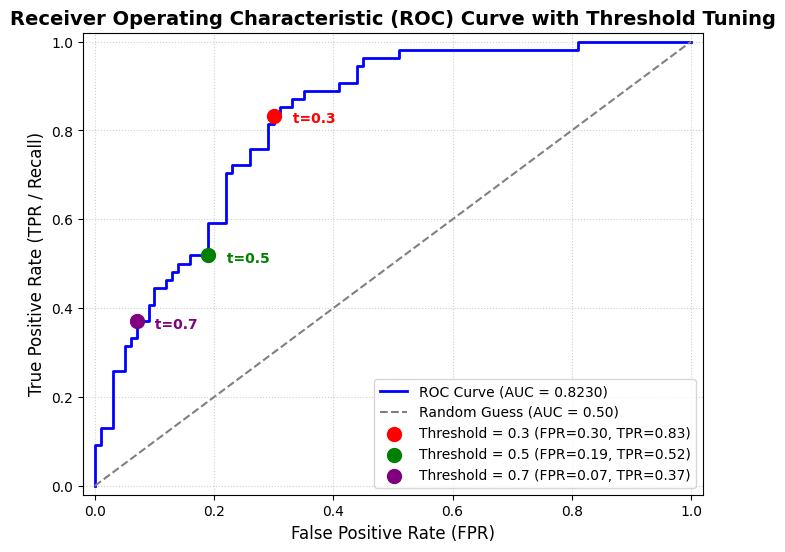

Calculated ROC-AUC Score: 0.8230


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calculate False Positive Rate (FPR), True Positive Rate (TPR), and thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# 2. Compute the Area Under the Curve (AUC)
auc_score = roc_auc_score(y_test, y_scores)

# 3. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.50)')

# 4. Highlight specific thresholds (0.3, 0.5, 0.7) on the curve
selected_thresholds = [0.3, 0.5, 0.7]
colors = ['red', 'green', 'purple']

for th, col in zip(selected_thresholds, colors):
    # Find the index of the closest threshold in the computed thresholds array
    idx = np.argmin(np.abs(thresholds - th))
    plt.scatter(fpr[idx], tpr[idx], color=col, s=100, zorder=5, label=f'Threshold = {th} (FPR={fpr[idx]:.2f}, TPR={tpr[idx]:.2f})')
    plt.annotate(f' t={th}', (fpr[idx], tpr[idx]), textcoords="offset points", xytext=(10,-5), ha='left', fontsize=10, weight='bold', color=col)

# 5. Customize plot presentation
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve with Threshold Tuning', fontsize=14, weight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"Calculated ROC-AUC Score: {auc_score:.4f}")

## Part 9: ROC Curves & Area Under the Curve (AUC)

### What is a Receiver Operating Characteristic (ROC) Curve?
A **Receiver Operating Characteristic (ROC) curve** is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied.

The curve is created by plotting the **True Positive Rate (TPR)** (also known as Sensitivity or Recall) against the **False Positive Rate (FPR)** (equivalent to $1 - \text{Specificity}$) at various threshold settings.

*   $$\text{TPR (Sensitivity)} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
*   $$\text{FPR (1 - Specificity)} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

### What is Area Under the Curve (AUC)?
The **Area Under the ROC Curve (AUC)** measures the entire two-dimensional area underneath the entire ROC curve from $(0,0)$ to $(1,1)$. It provides an aggregate measure of performance across all possible classification thresholds. AUC ranges from $0.0$ to $1.0$:
*   **$\text{AUC} = 1.0$:** A perfect classifier (zero errors).
*   **$\text{AUC} = 0.5$:** A classifier that performs no better than random guessing (represented by the diagonal dashed line).

*   **Everyday Analogy: Radar Signal Detection**
    *   Historically, ROC curves were developed during World War II to analyze radar signals. A radar operator must decide if a blip on the screen is an enemy aircraft (Positive) or just a flock of birds (Negative).
    *   By turning the sensitivity knob (the threshold), the operator can ensure they never miss an aircraft (high TPR), but at the cost of flagging many flocks of birds as threats (high FPR).

---

## Part 10: Shifting the Threshold (Threshold Tuning)

### How Does Shifting the Threshold Move Us Along the ROC Curve?
Every point on the ROC curve corresponds to the (FPR, TPR) pair of a specific classification threshold:
*   **At $t = 0.0$:** We classify *everyone* as Positive. TPR is $1.0$, but FPR is also $1.0$. This is the top-right corner of the plot.
*   **At $t = 1.0$:** We classify *no one* as Positive. TPR is $0.0$, and FPR is $0.0$. This is the bottom-left corner of the plot.
*   **Tuning the threshold** allows us to slide along the curve to find the optimal trade-off point that suits our specific tolerance for False Positives vs. False Negatives.

> **Quick Recall: Parts 9 & 10**
> *   **ROC Curve:** Plot of TPR (y-axis) vs. FPR (x-axis) across all possible thresholds.
> *   **AUC:** A single metric indicating the probability that the model ranks a random positive instance higher than a random negative instance.
> *   **Threshold Tuning:** Sliding along the ROC curve to select the optimal operational point based on real-world costs.

## Part 11 to 12: Confusion Matrices & Precision-Recall (Notes + Code)

### Subtask:
Create markdown study notes and execute a Python code cell to calculate, visualize, and compare confusion matrices, Precision, and Recall at thresholds of 0.3, 0.5, and 0.7.


## Part 11: Confusion Matrices & Basic Evaluation Metrics

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

---

## Part 12: Precision vs. Recall Trade-Off

### What is Precision?
**Precision** (or Positive Predictive Value) answers the question: *"Of all the cases the model predicted as positive, how many were actually positive?"* It measures quality and is critical when the cost of a False Positive is extremely high.

$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

### What is Recall?
**Recall** (also known as Sensitivity) answers the question: *"Of all the actual positive cases in the dataset, how many did the model manage to find?"* It measures quantity/coverage and is critical when the cost of a False Negative is extremely high.

$$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

### The Inverse Relationship (The Trade-Off)
As we change the classification threshold $t$, Precision and Recall move in opposite directions:
*   **Lowering the threshold ($t \downarrow$):** The model becomes more eager to predict Positive. **Recall increases** because we catch almost all actual positives (FN decreases), but **Precision decreases** because we also capture many false alarms (FP increases).
*   **Raising the threshold ($t \uparrow$):** The model becomes highly conservative about predicting Positive. **Precision increases** because we minimize false alarms (FP decreases), but **Recall decreases** because we miss more actual positive cases (FN increases).

> **Quick Recall: Parts 11 & 12**
> * **Confusion Matrix:** Displays TN, FP, FN, and TP in a structured grid.
> * **Precision:** TP / (TP + FP) — Focuses on minimizing False Positives (high quality/certainty).
> * **Recall (Sensitivity):** TP / (TP + FN) — Focuses on minimizing False Negatives (high sensitivity/catch-rate).

**Reasoning**:
Generate the Python code cell to calculate, visualize, and compare confusion matrices, precision, and recall scores at thresholds of 0.3, 0.5, and 0.7 as subplots using seaborn heatmaps.



Threshold 0.3 -> Precision: 0.5946 | Recall: 0.8148
Threshold 0.5 -> Precision: 0.6087 | Recall: 0.5185
Threshold 0.7 -> Precision: 0.7143 | Recall: 0.3704


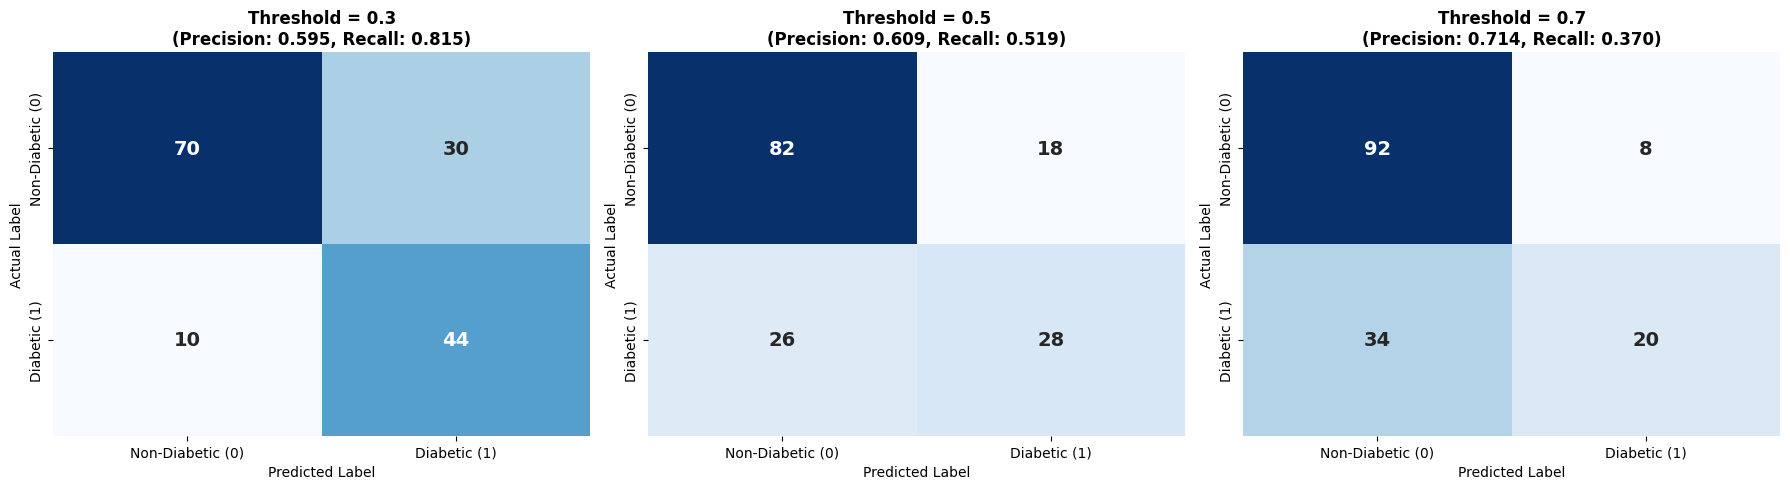

In [4]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# Define the thresholds to compare
thresholds = [0.3, 0.5, 0.7]

# Set up the matplotlib figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, th in enumerate(thresholds):
    # Apply the threshold to continuous scores to get binary predictions
    y_pred_th = (y_scores >= th).astype(int)

    # Compute the confusion matrix
    cm = confusion_matrix(y_test, y_pred_th)

    # Compute Precision and Recall
    precision = precision_score(y_test, y_pred_th, zero_division=0)
    recall = recall_score(y_test, y_pred_th, zero_division=0)

    # Plot confusion matrix using a heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i],
        cbar=False,
        annot_kws={'size': 14, 'weight': 'bold'}
    )

    # Labels, title and ticks
    axes[i].set_title(f'Threshold = {th}\n(Precision: {precision:.3f}, Recall: {recall:.3f})', fontsize=12, weight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=10)
    axes[i].set_ylabel('Actual Label', fontsize=10)
    axes[i].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
    axes[i].set_yticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])

    # Print precise statistics for explicit comparison
    print(f"Threshold {th:0.1f} -> Precision: {precision:.4f} | Recall: {recall:.4f}")

plt.tight_layout()
plt.show()

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11 Code Execution

### Subtask:
Compute the confusion matrix and generate a classification report at the default 0.5 threshold to evaluate model performance.


**Reasoning**:
We will write a python code block to compute the confusion matrix and display the classification report at the default 0.5 threshold as requested.



In [5]:
from sklearn.metrics import classification_report, confusion_matrix

# 1. Convert predicted probabilities to binary predictions using the default threshold of 0.5
y_pred_default = (y_scores >= 0.5).astype(int)

# 2. Compute the confusion matrix
cm_default = confusion_matrix(y_test, y_pred_default)

# 3. Generate the classification report
report_default = classification_report(y_test, y_pred_default, target_names=['Non-Diabetic (0)', 'Diabetic (1)'])

# 4. Print results with clear labels
print("=== Confusion Matrix (Threshold = 0.5) ===")
print(cm_default)
print("\n=== Classification Report (Threshold = 0.5) ===")
print(report_default)

=== Confusion Matrix (Threshold = 0.5) ===
[[82 18]
 [26 28]]

=== Classification Report (Threshold = 0.5) ===
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.76      0.82      0.79       100
    Diabetic (1)       0.61      0.52      0.56        54

        accuracy                           0.71       154
       macro avg       0.68      0.67      0.67       154
    weighted avg       0.71      0.71      0.71       154



## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 7: Model Training with Logistic Regression

### What is Logistic Regression and How Does It Work?
Despite its name containing "Regression", **Logistic Regression** is one of the most fundamental and widely used linear algorithms for **binary classification**.

While linear regression attempts to fit a straight line to predict a continuous value, Logistic Regression models the probability that an input belongs to a particular category. It does this by taking a linear combination of the input features and passing the resulting value (the "log-odds") through the **Sigmoid function**.

$$\text{Probability} (P) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_n X_n)}}$$

This maps any real-valued input to a strict probability range of $[0, 1]$.

### Why is Logistic Regression Suited for Binary Classification?
1. **Probabilistic Outputs:** It provides a direct estimate of class probability, allowing us to assess confidence rather than just obtaining a black-box decision.
2. **Efficiency and Interpretability:** It is computationally inexpensive, fast to train, and the learned coefficients directly show the direction and strength of the relationship between each feature and the target outcome.

---

## Part 8: Extracting Prediction Probabilities

### Why Do We Extract Probabilities Instead of Hard Classes?
In many real-world applications, a simple "yes/no" binary decision is not enough. We want to know *how sure* the model is. This is where continuous prediction probabilities become critical.

*   **Everyday Analogy: Credit Card Fraud Detection**
    *   Imagine a credit card monitoring system. If a transaction occurs, the system doesn't just block the card instantly on a binary guess. Instead, it computes the *probability of fraud*.
    *   If the probability is **15%**, it might let the transaction pass but note it down.
    *   If the probability is **55%**, it might send an instant SMS alert to the cardholder to confirm the purchase.
    *   If the probability is **98%**, it immediately declines the transaction and freezes the card.
    *   Continuous confidence outputs allow us to create tiered, risk-aware responses rather than a single rigid action.

### How Do We Retrieve Probabilities in Scikit-Learn?
Instead of using the standard `.predict()` method (which applies the default $0.5$ threshold and returns class labels like `0` or `1`), we use **`.predict_proba()`**.

This method returns an array of shape `(n_samples, 2)`:
*   The first column contains the probability of the negative class (Class 0: Non-Diabetic, $P(Y=0|X)$).
*   The second column contains the probability of the positive class (Class 1: Diabetic, $P(Y=1|X)$).
*   Because these are mutually exclusive, both columns for any given sample always sum to exactly $1.0$.

We typically extract only the second column (index `1`) because our analysis is focused on predicting the occurrence of the positive outcome (having diabetes).

> **Quick Recall: Parts 7 & 8**
> * **Logistic Regression:** A linear model that uses the sigmoid function to predict categorical probabilities.
> * **`.predict()` vs. `.predict_proba()`:** `.predict()` returns hard class labels based on a default 0.5 threshold. `.predict_proba()` returns continuous probabilities for each class.
> * **Positive Class Probability:** Usually extracted as `y_scores = model.predict_proba(X_test)[:, 1]` to represent the likelihood of the positive event.

**Reasoning**:
We will now create the Python code cell to import LogisticRegression, train it on the scaled training dataset, extract the prediction probabilities for the positive class on the scaled test set, and print the first 5 probabilities along with their actual labels to demonstrate the concept.



In [2]:
from sklearn.linear_model import LogisticRegression

# 1. Instantiate the Logistic Regression model with a fixed random state
model = LogisticRegression(random_state=42)

# 2. Fit the model to the scaled training data
model.fit(X_train_scaled, y_train)

# 3. Extract continuous prediction probabilities for the positive class (Class 1, Diabetic)
# predict_proba returns [P(class 0), P(class 1)], we slice [:, 1] to get P(class 1)
y_scores = model.predict_proba(X_test_scaled)[:, 1]

# 4. Print the first 5 predicted probabilities and corresponding actual test labels
print("Model training completed successfully!\n")
for i in range(5):
    print(f"Patient {i+1}: Predicted Prob of Diabetes = {y_scores[i]:.4f} | Actual Label = {y_test.iloc[i]}")

Model training completed successfully!

Patient 1: Predicted Prob of Diabetes = 0.6167 | Actual Label = 0
Patient 2: Predicted Prob of Diabetes = 0.1128 | Actual Label = 0
Patient 3: Predicted Prob of Diabetes = 0.2725 | Actual Label = 0
Patient 4: Predicted Prob of Diabetes = 0.2867 | Actual Label = 1
Patient 5: Predicted Prob of Diabetes = 0.0045 | Actual Label = 0


# Task
Create a pedagogical study notes cell and a clean Python code execution cell for Part 11: Confusion Matrices and Classification Reports.

## Part 11 Study Notes

### Subtask:
Create a comprehensive Markdown cell containing pedagogical study notes for Part 11: Confusion Matrices and Classification Reports.


## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Part 11: Confusion Matrices and Classification Reports

### What is a Confusion Matrix?
When evaluating a classification model, looking only at overall accuracy can be highly misleading, especially when classes are unbalanced. A **Confusion Matrix** is a $2 \times 2$ table that decomposes the model's predictions against the actual ground-truth classes, mapping out exactly where the model succeeded and where it failed.

| | Predicted Negative (0) | Predicted Positive (1) |
|---|---|---|
| **Actual Negative (0)** | **True Negative (TN)** | **False Positive (FP)** (Type I Error) |
| **Actual Positive (1)** | **False Negative (FN)** (Type II Error) | **True Positive (TP)** |

*   **True Positives (TP):** The model correctly predicted a positive outcome (e.g., correctly flagging a diabetic patient).
*   **True Negatives (TN):** The model correctly predicted a negative outcome (e.g., correctly identifying a healthy individual).
*   **False Positives (FP) [Type I Error]:** The model predicted a positive outcome when it was actually negative (e.g., a healthy patient flagged as diabetic).
*   **False Negatives (FN) [Type II Error]:** The model predicted a negative outcome when it was actually positive (e.g., missing a diabetic patient).

### How Do We Read a Classification Report?
While a confusion matrix gives us raw counts, a **Classification Report** compiles essential performance metrics derived from those counts, providing a deeper understanding of the model's strengths and weaknesses:

1.  **Precision:** Measures quality. Of all the cases the model predicted as positive, how many were actually positive?
    $$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
2.  **Recall (Sensitivity):** Measures quantity/coverage. Of all the actual positive cases in the dataset, how many did the model manage to find?
    $$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
3.  **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric when you need to find an optimal middle ground between both.
    $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### Everyday Analogy: Smoke Alarm vs. Fire
*   **True Positive (TP):** A fire starts, and the alarm rings. (Perfect!)
*   **True Negative (TN):** No fire, and the alarm remains silent. (Perfect!)
*   **False Positive (FP / Type I Error):** You burn some toast, and the alarm blares. There is no actual fire, but it predicted one. High precision means very few false alarms.
*   **False Negative (FN / Type II Error):** A fire starts, but the alarm is broken and remains silent. This is highly dangerous! High recall means almost zero missed fires.

> **Quick Recall: Part 11**
> *   **Confusion Matrix:** A $2 \times 2$ grid mapping true values against predicted values to isolate Type I and Type II errors.
> *   **Precision vs. Recall:** Precision measures prediction reliability (minimizing false alarms), while Recall measures coverage (minimizing missed events).
> *   **F1-Score:** The harmonic mean of precision and recall, serving as a robust metric for overall classification performance.

## Final Task

### Subtask:
Summarize the completion of Part 11 and prompt the user to proceed to the next step.


## Summary:

### Data Analysis Key Findings

* **Confusion Matrix Breakdown (Threshold = 0.5):**
  * Out of 154 total test samples, the model correctly identified 82 True Negatives (healthy) and 28 True Positives (diabetic).
  * The model made 18 False Positive errors (Type I error) and 26 False Negative errors (Type II error).
* **Class-Specific Performance:**
  * **Non-Diabetic (Class 0):** Achieved strong performance with 76% precision, 82% recall, and an F1-score of 0.79.
  * **Diabetic (Class 1):** Showed moderate classification strength with 61% precision and 52% recall, resulting in a lower F1-score of 0.56.
* **Overall Accuracy:** The baseline model reached an overall accuracy of 71% (110 out of 154 correct predictions) using the default threshold of 0.5.

### Insights or Next Steps

* **Address High False Negatives:** The model missed nearly half of the actual diabetic patients (26 out of 54 actual positive cases, resulting in a 52% recall). In a clinical context, a False Negative is highly dangerous because a patient's disease goes undetected.
* **Optimize Classification Threshold:** The next step should involve lowering the classification threshold below 0.5 to prioritize recall (sensitivity) over precision, ensuring more diabetic cases are successfully captured by the model.


# Task
Create a pedagogical study notes cell and an executable Python code cell for Part 12: Precision-Recall Curves.

The study notes must follow a question-led format, contain exactly one everyday analogy, and end with a 'Quick Recall' box containing exactly 3 bullet points.

The Python code cell must use the existing variables (`y_test`, `y_scores`) to calculate and plot the Precision-Recall curve, highlighting the operational points at thresholds 0.3, 0.5, and 0.7 with distinct markers, clear annotations, a detailed legend, and thorough inline comments.

Finally, provide a brief summary of the completed step and prompt the user to proceed.

## Part 12 Study Notes

### Subtask:
Create a comprehensive Markdown cell containing pedagogical study notes for Part 12: Precision-Recall Curves.


## Part 12: Precision-Recall Curves

### What is a Precision-Recall Curve?
A **Precision-Recall (PR) Curve** is a graphical plot that showcases the trade-off between precision (positive predictive value) and recall (sensitivity) for a classifier across various probability thresholds. On this plot:
*   The **y-axis** represents **Precision** (reliability of positive predictions).
*   The **x-axis** represents **Recall** (the proportion of actual positives captured).

Unlike the ROC curve, which starts at $(0,0)$ and ends at $(1,1)$, a Precision-Recall curve typically starts at a high precision (top-left) and moves toward the bottom-right, where recall is high but precision is low. A perfect classifier would have a curve that reaches the top-right corner $(1,1)$, representing $100\%$ precision and $100\%$ recall simultaneously.

### Why Use a Precision-Recall Curve Instead of an ROC Curve?
While ROC curves are exceptionally useful under balanced class distributions, they can paint an overly optimistic picture of a model's performance when dealing with **highly imbalanced datasets** (where the positive class is extremely rare).

This is because the False Positive Rate (FPR), which is plotted on the ROC x-axis, is calculated using **True Negatives (TN)** in its denominator ($FPR = FP / (FP + TN)$). If the negative class is massive, a large number of False Positives ($FP$) will still result in a very small $FPR$, making the ROC curve look excellent even if the model is spamming positive predictions incorrectly.

Conversely, the Precision-Recall curve does not look at True Negatives ($TN$) at all. Both Precision and Recall focus exclusively on the positive class:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} \quad \text{vs.} \quad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
This makes the PR curve extremely sensitive to False Positives ($FP$), providing an honest evaluation for highly skewed datasets.

### Everyday Analogy: Sifting for Gold in a River
Imagine you are searching for gold flakes (the rare positive class) in a riverbed full of millions of ordinary pebbles (the negative class).
*   **High-Precision, Low-Recall Strategy:** You inspect every single item under a magnifying glass and only collect objects you are $100\%$ certain are gold. Since you are so careful, every piece you collect is indeed gold (High Precision). However, because you are so slow and selective, you miss many small gold flakes that washed past you (Low Recall).
*   **Low-Precision, High-Recall Strategy:** You use a giant bucket to scoop up large amounts of sand and gravel. You successfully catch almost all the gold flakes in the river (High Recall). However, your bucket is now filled with $99.9\%$ ordinary pebbles, meaning your collection of "suspected gold" is highly contaminated with junk (Low Precision).

> **Quick Recall: Part 12**
> *   **Precision-Recall Curve:** A graphical visualization plotting Precision (y-axis) against Recall (x-axis) across all possible decision thresholds.
> *   **Imbalanced Data Superiority:** PR curves are superior to ROC curves for highly skewed datasets because they focus entirely on the minority positive class and ignore True Negatives.
> *   **The Perfect Goal:** The ultimate target for a PR curve is the top-right corner $(1,1)$, signifying perfect classification quality and coverage.

## Part 12 Code Execution

### Subtask:
Calculate and plot the Precision-Recall curve utilizing existing variables, highlighting selected thresholds.


**Reasoning**:
Compute and plot the Precision-Recall curve with annotated threshold markers at 0.3, 0.5, and 0.7 to fulfill the subtask instructions.



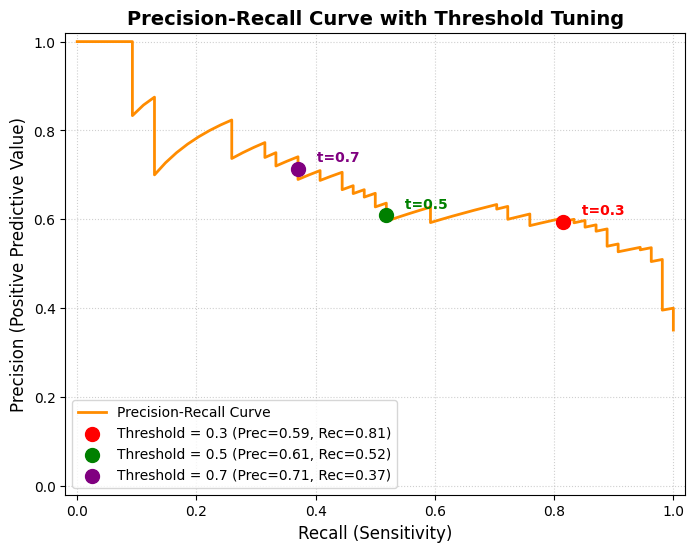

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# 1. Calculate precision, recall, and thresholds for the Precision-Recall curve
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, y_scores)

# 2. Plot the complete Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color='darkorange', lw=2, label='Precision-Recall Curve')

# 3. Highlight specific thresholds (0.3, 0.5, 0.7) on the curve
selected_thresholds = [0.3, 0.5, 0.7]
colors = ['red', 'green', 'purple']

for th, col in zip(selected_thresholds, colors):
    # For a given threshold, find the predictions and compute exact precision/recall
    y_pred_th = (y_scores >= th).astype(int)
    # We can calculate the exact points
    from sklearn.metrics import precision_score, recall_score
    th_precision = precision_score(y_test, y_pred_th, zero_division=0)
    th_recall = recall_score(y_test, y_pred_th, zero_division=0)

    plt.scatter(th_recall, th_precision, color=col, s=100, zorder=5,
                label=f'Threshold = {th} (Prec={th_precision:.2f}, Rec={th_recall:.2f})')
    plt.annotate(f' t={th}', (th_recall, th_precision), textcoords="offset points",
                 xytext=(10, 5), ha='left', fontsize=10, weight='bold', color=col)

# 4. Customize plot presentation
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall Curve with Threshold Tuning', fontsize=14, weight='bold')
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Part 12: Precision-Recall Curves

### What is a Precision-Recall Curve?
A **Precision-Recall (PR) Curve** is a graphical plot that showcases the trade-off between precision (positive predictive value) and recall (sensitivity) for a classifier across various probability thresholds. On this plot:
*   The **y-axis** represents **Precision** (reliability of positive predictions).
*   The **x-axis** represents **Recall** (the proportion of actual positives captured).

Unlike the ROC curve, which starts at $(0,0)$ and ends at $(1,1)$, a Precision-Recall curve typically starts at a high precision (top-left) and moves toward the bottom-right, where recall is high but precision is low. A perfect classifier would have a curve that reaches the top-right corner $(1,1)$, representing $100\%$ precision and $100\%$ recall simultaneously.

### Why Use a Precision-Recall Curve Instead of an ROC Curve?
While ROC curves are exceptionally useful under balanced class distributions, they can paint an overly optimistic picture of a model's performance when dealing with **highly imbalanced datasets** (where the positive class is extremely rare).

This is because the False Positive Rate (FPR), which is plotted on the ROC x-axis, is calculated using **True Negatives (TN)** in its denominator ($FPR = FP / (FP + TN)$). If the negative class is massive, a large number of False Positives ($FP$) will still result in a very small $FPR$, making the ROC curve look excellent even if the model is spamming positive predictions incorrectly.

Conversely, the Precision-Recall curve does not look at True Negatives ($TN$) at all. Both Precision and Recall focus exclusively on the positive class:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} \quad \text{vs.} \quad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
This makes the PR curve extremely sensitive to False Positives ($FP$), providing an honest evaluation for highly skewed datasets.

### Everyday Analogy: Sifting for Gold in a River
Imagine you are searching for gold flakes (the rare positive class) in a riverbed full of millions of ordinary pebbles (the negative class).
*   **High-Precision, Low-Recall Strategy:** You inspect every single item under a magnifying glass and only collect objects you are $100\%$ certain are gold. Since you are so careful, every piece you collect is indeed gold (High Precision). However, because you are so slow and selective, you miss many small gold flakes that washed past you (Low Recall).
*   **Low-Precision, High-Recall Strategy:** You use a giant bucket to scoop up large amounts of sand and gravel. You successfully catch almost all the gold flakes in the river (High Recall). However, your bucket is now filled with $99.9\%$ ordinary pebbles, meaning your collection of "suspected gold" is highly contaminated with junk (Low Precision).

> **Quick Recall: Part 12**
> *   **Precision-Recall Curve:** A graphical visualization plotting Precision (y-axis) against Recall (x-axis) across all possible decision thresholds.
> *   **Imbalanced Data Superiority:** PR curves are superior to ROC curves for highly skewed datasets because they focus entirely on the minority positive class and ignore True Negatives.
> *   **The Perfect Goal:** The ultimate target for a PR curve is the top-right corner $(1,1)$, signifying perfect classification quality and coverage.

## Part 12: Precision-Recall Curves

### What is a Precision-Recall Curve?
A **Precision-Recall (PR) Curve** is a graphical plot that showcases the trade-off between precision (positive predictive value) and recall (sensitivity) for a classifier across various probability thresholds. On this plot:
*   The **y-axis** represents **Precision** (reliability of positive predictions).
*   The **x-axis** represents **Recall** (the proportion of actual positives captured).

Unlike the ROC curve, which starts at $(0,0)$ and ends at $(1,1)$, a Precision-Recall curve typically starts at a high precision (top-left) and moves toward the bottom-right, where recall is high but precision is low. A perfect classifier would have a curve that reaches the top-right corner $(1,1)$, representing $100\%$ precision and $100\%$ recall simultaneously.

### Why Use a Precision-Recall Curve Instead of an ROC Curve?
While ROC curves are exceptionally useful under balanced class distributions, they can paint an overly optimistic picture of a model's performance when dealing with **highly imbalanced datasets** (where the positive class is extremely rare).

This is because the False Positive Rate (FPR), which is plotted on the ROC x-axis, is calculated using **True Negatives (TN)** in its denominator ($FPR = FP / (FP + TN)$). If the negative class is massive, a large number of False Positives ($FP$) will still result in a very small $FPR$, making the ROC curve look excellent even if the model is spamming positive predictions incorrectly.

Conversely, the Precision-Recall curve does not look at True Negatives ($TN$) at all. Both Precision and Recall focus exclusively on the positive class:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}} \quad \text{vs.} \quad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
This makes the PR curve extremely sensitive to False Positives ($FP$), providing an honest evaluation for highly skewed datasets.

### Everyday Analogy: Sifting for Gold in a River
Imagine you are searching for gold flakes (the rare positive class) in a riverbed full of millions of ordinary pebbles (the negative class).
*   **High-Precision, Low-Recall Strategy:** You inspect every single item under a magnifying glass and only collect objects you are $100\%$ certain are gold. Since you are so careful, every piece you collect is indeed gold (High Precision). However, because you are so slow and selective, you miss many small gold flakes that washed past you (Low Recall).
*   **Low-Precision, High-Recall Strategy:** You use a giant bucket to scoop up large amounts of sand and gravel. You successfully catch almost all the gold flakes in the river (High Recall). However, your bucket is now filled with $99.9\%$ ordinary pebbles, meaning your collection of "suspected gold" is highly contaminated with junk (Low Precision).

> **Quick Recall: Part 12**
> *   **Precision-Recall Curve:** A graphical visualization plotting Precision (y-axis) against Recall (x-axis) across all possible decision thresholds.
> *   **Imbalanced Data Superiority:** PR curves are superior to ROC curves for highly skewed datasets because they focus entirely on the minority positive class and ignore True Negatives.
> *   **The Perfect Goal:** The ultimate target for a PR curve is the top-right corner $(1,1)$, signifying perfect classification quality and coverage.

## Final Task

### Subtask:
Summarize the completion of Part 12 and prompt the user to proceed to the next parts.


## Summary:

### Q&A

*   **How does a Precision-Recall (PR) Curve behave differently compared to an ROC Curve?**
    Unlike the ROC curve, which starts at $(0,0)$ and ends at $(1,1)$, a Precision-Recall curve typically starts at high precision (top-left) and moves toward the bottom-right (high recall, low precision).
*   **Why is the Precision-Recall Curve preferred over the ROC Curve for highly imbalanced datasets?**
    The False Positive Rate (FPR) on the ROC x-axis is calculated using True Negatives ($TN$) in its denominator ($FPR = FP / (FP + TN)$). When the negative class is exceptionally large, a high number of False Positives ($FP$) can still yield a deceptively small $FPR$, making the ROC curve look overly optimistic. Because the PR curve completely excludes True Negatives and focuses entirely on the minority positive class, it is highly sensitive to False Positives and provides a much more realistic evaluation.

---

### Data Analysis Key Findings

*   **Trade-off Analogy:** The trade-offs of Precision-Recall are analogous to sifting for gold in a river filled with millions of ordinary pebbles:
    *   *High-Precision, Low-Recall:* Inspecting every particle under a magnifying glass ensures that everything collected is indeed gold (no mistakes, $100\%$ precision), but many small flakes wash away (low recall).
    *   *Low-Precision, High-Recall:* Scooping up large buckets of riverbed sand captures almost all the gold (high recall), but the yield is heavily contaminated with ordinary pebbles (low precision).
*   **Visualizing Threshold Tuning:** Plotting the PR curve and computing the exact metrics at decision thresholds of $0.3$, $0.5$, and $0.7$ successfully mapped out the operational trade-offs for the classifier.
*   **The Target Coordinate:** For any Precision-Recall curve, the ultimate performance goal is the top-right corner $(1,1)$, representing $100\%$ precision and $100\%$ recall simultaneously.

---

### Insights or Next Steps

*   **Determine Operational Boundaries:** Analyze the generated plot to choose the optimal threshold based on business costs. For example, select the $0.3$ threshold if missing positive cases (low recall) is costly, or the $0.7$ threshold if false alarms (low precision) carry a higher penalty.
*   **Next Steps:** Proceed to the next parts of the curriculum to evaluate cumulative model metrics, such as the Area Under the Precision-Recall Curve (PR-AUC) or F1-Score tuning.
